In [1]:
import re
import random
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

In [2]:
torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [3]:
CSV_PATH = r"C:\Users\KUNAL\Downloads\Dataset_DL\Dataset_DL\IMDB_Dataset.csv"

MAX_VOCAB_SIZE = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 128
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 5

df = pd.read_csv(CSV_PATH)

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


In [4]:
df = df.dropna(subset=["review", "sentiment"])

texts = df["review"].astype(str).tolist()

labels = df["sentiment"].str.lower().map({
    "negative": 0,
    "positive": 1
}).tolist()

print("Total reviews:", len(texts))
print("Positive reviews:", labels.count(1))
print("Negative reviews:", labels.count(0))

Total reviews: 50000
Positive reviews: 25000
Negative reviews: 25000


In [5]:
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts,
    temp_labels,
    test_size=0.5,
    random_state=42,
    stratify=temp_labels
)

print("Training samples:", len(train_texts))
print("Validation samples:", len(val_texts))
print("Testing samples:", len(test_texts))

Training samples: 40000
Validation samples: 5000
Testing samples: 5000


In [6]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())


counter = Counter()

for review in train_texts:
    counter.update(tokenize(review))


vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 10000


In [7]:
class IMDBDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        tokens = tokenize(self.texts[index])[:MAX_LENGTH]

        encoded = [
            vocab.get(word, 1)
            for word in tokens
        ]

        if len(encoded) == 0:
            encoded = [1]

        text = torch.tensor(encoded, dtype=torch.long)

        label = torch.tensor(
            self.labels[index],
            dtype=torch.float32
        )

        return text, label

In [8]:
train_dataset = IMDBDataset(train_texts, train_labels)

val_dataset = IMDBDataset(val_texts, val_labels)

test_dataset = IMDBDataset(test_texts, test_labels)

print("Datasets created successfully")

Datasets created successfully


In [9]:
def collate_batch(batch):

    texts, labels = zip(*batch)

    lengths = torch.tensor([
        len(text) for text in texts
    ])

    texts = pad_sequence(
        texts,
        batch_first=True,
        padding_value=0
    )

    labels = torch.stack(labels)

    return texts, lengths, labels

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

print("DataLoaders created successfully")

DataLoaders created successfully


In [11]:
class LSTMClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            len(vocab),
            EMBEDDING_DIM,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            EMBEDDING_DIM,
            HIDDEN_DIM,
            batch_first=True
        )

        self.fc = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, text, lengths):

        embedded = self.embedding(text)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        output, (hidden, cell) = self.lstm(packed)

        hidden = hidden[-1]

        output = self.fc(hidden)

        return output.squeeze(1)


model = LSTMClassifier().to(device)

print(model)

LSTMClassifier(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (lstm): LSTM(128, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [12]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [13]:
train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for texts, lengths, labels in train_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts, lengths)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = (outputs >= 0).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)

    train_accuracy = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for texts, lengths, labels in val_loader:

            texts = texts.to(device)
            labels = labels.to(device)

            outputs = model(texts, lengths)

            predictions = (outputs >= 0).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = 100 * val_correct / val_total

    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.6184 Train Accuracy: 64.74% Validation Accuracy: 75.70%
Epoch [2/5] Loss: 0.4670 Train Accuracy: 78.73% Validation Accuracy: 76.72%
Epoch [3/5] Loss: 0.3989 Train Accuracy: 82.70% Validation Accuracy: 81.70%
Epoch [4/5] Loss: 0.3274 Train Accuracy: 86.60% Validation Accuracy: 85.60%
Epoch [5/5] Loss: 0.2687 Train Accuracy: 89.35% Validation Accuracy: 86.36%


In [14]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for texts, lengths, labels in test_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        outputs = model(texts, lengths)

        predictions = (outputs >= 0).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print("Final Test Accuracy:", round(test_accuracy, 2), "%")

Final Test Accuracy: 85.68 %


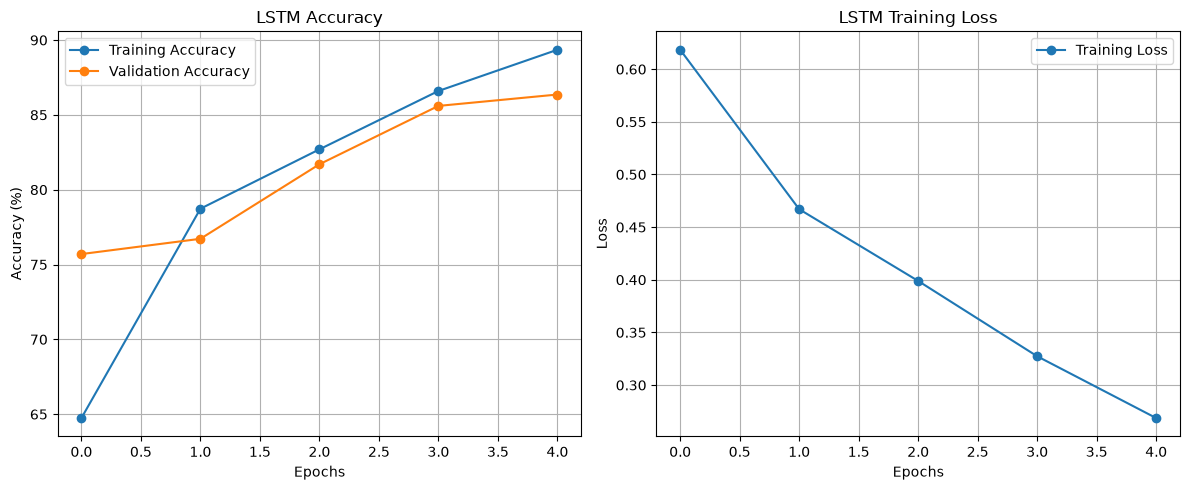

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(train_accuracies, label="Training Accuracy", marker="o")
plt.plot(val_accuracies, label="Validation Accuracy", marker="o")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("LSTM Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(train_losses, label="Training Loss", marker="o")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Training Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [16]:
def predict_sentiment(review):

    model.eval()

    tokens = tokenize(review)[:MAX_LENGTH]

    encoded = [
        vocab.get(word, 1)
        for word in tokens
    ]

    if len(encoded) == 0:
        encoded = [1]

    text = torch.tensor(
        encoded,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    lengths = torch.tensor([len(encoded)])

    with torch.no_grad():

        output = model(text, lengths)

        probability = torch.sigmoid(output).item()

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    return sentiment, probability

In [17]:
sample_indices = random.sample(
    range(len(test_texts)),
    min(5, len(test_texts))
)

probabilities = []

for i, index in enumerate(sample_indices):

    review = test_texts[index]
    actual_label = test_labels[index]

    sentiment, probability = predict_sentiment(review)

    probabilities.append(probability)

    actual = "Positive" if actual_label == 1 else "Negative"

    print("\nSample:", i+1)
    print("Review:", review[:150], "...")
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", sentiment)
    print("Positive Probability:", round(probability, 4))


Sample: 1
Review: There were a lot of 50's sci-fi movies. They were big draws for the Drive-in theaters. A lot of them were crappy even back then. This movie and 'The D ...
Actual Sentiment: Positive
Predicted Sentiment: Positive
Positive Probability: 0.911

Sample: 2
Review: For anyone who has seen and fallen in love with the stage musical A CHORUS LINE, the movie is a shoddy substitute. Not only are songs cut, but unneces ...
Actual Sentiment: Negative
Predicted Sentiment: Positive
Positive Probability: 0.5348

Sample: 3
Review: From the opening scene aboard a crowded train where a ruthless pickpocket is at work (RICHARD WIDMARK) stealing from a woman's purse (JEAN PETERS), PI ...
Actual Sentiment: Positive
Predicted Sentiment: Positive
Positive Probability: 0.7664

Sample: 4
Review: I liked this movie, Although halfway through it, I was able to tell who the secret admirer was.<br /><br />I am also wondering if it was based on a tr ...
Actual Sentiment: Positive
Predicted Sentiment:

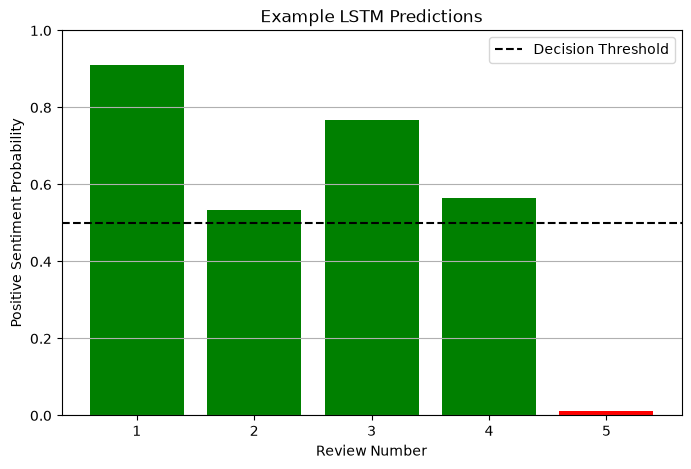

In [18]:
plt.figure(figsize=(8, 5))

colors = [
    "green" if p >= 0.5 else "red"
    for p in probabilities
]

plt.bar(
    range(1, len(probabilities)+1),
    probabilities,
    color=colors
)

plt.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    label="Decision Threshold"
)

plt.xlabel("Review Number")
plt.ylabel("Positive Sentiment Probability")
plt.title("Example LSTM Predictions")

plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y")

plt.show()